# 06 · Informe reproducible y evidencia experimental EP3

**Proyecto:** estimación de popularidad histórica de canciones de Spotify Tracks  
**Asignatura:** Machine Learning · Duoc UC · 2026  
**Equipo:** Lucas Moncada, Ignacio Silva y César Rojas

Este notebook consolida preparación, EDA, regresión, selección de hiperparámetros, evaluación por canción y por artista principal, diagnóstico de segmentos, K-Means/PCA y conclusiones. Parte del CSV original y vuelve a ejecutar los experimentos; no lee tablas de resultados previos para producir las métricas. Los datos de prueba permanecen separados de toda selección.

> **Ejecución completa:** se requieren dependencias de `pyproject.toml` y kernel del entorno del proyecto (`uv sync --all-groups`; `uv run python -m ipykernel install --user --name python3 --display-name "Python 3.12 (spotify-popularity-analysis)"`). Ejecutar todas las celdas en orden desde un kernel reiniciado. La búsqueda de RF y la validación agrupada realizan ajustes completos sobre la muestra, por lo que pueden tardar decenas de minutos. No ejecutar con `--allow-errors`.

Las pruebas aleatoria y agrupada responden preguntas distintas. La primera estima desempeño al retener canciones, permitiendo artistas presentes en ambos lados. La segunda reserva artistas principales. Ambas son evaluaciones retrospectivas y no sustituyen una prueba temporal de canciones futuras.


## 1. Datos, preparación y controles

Se carga el archivo original versionado y se aplica la función de preparación del proyecto. Se registran huella SHA-256, versiones y controles para que el resultado se pueda rastrear. El dataset contiene repeticiones por género; una canción queda representada por un único `track_id` y con sus géneros consolidados.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from spotify_popularity.analysis.exploratory import validate_processed_dataset
from spotify_popularity.config import PROJECT_PATHS
from spotify_popularity.data.loader import load_raw_dataset
from spotify_popularity.data.preparation import prepare_modeling_dataset
from spotify_popularity.data.provenance import sha256_file
from spotify_popularity.modeling.protocol import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    SEED,
    GenreBinarizer,
    model_pipeline,
    primary_artist,
    regression_metrics,
    split_primary_artist_ids,
    split_track_ids,
    top_decile_kpi,
)

source_hash = sha256_file(PROJECT_PATHS.raw_dataset)
data, preparation = prepare_modeling_dataset(load_raw_dataset())
controls = validate_processed_dataset(data)
assert controls["shape"] == (89_740, 20)
assert controls["missing_cells"] == 0
assert controls["duplicate_track_ids"] == 0
assert controls["non_positive_durations"] == 0
assert controls["empty_genres"] == 0
assert data["popularity"].between(0, 100).all()

print(f"Fuente SHA-256: {source_hash}")
print(f"Python/scikit-learn/pandas: {sklearn.__version__} / {pd.__version__}")
print(f"Preparación: {preparation}")
display(pd.Series(controls, name="valor").to_frame())

Fuente SHA-256: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd
Python/scikit-learn/pandas: 1.9.0 / 2.3.3
Preparación: PreparationSummary(input_rows=114000, invalid_rows_removed=1, output_rows=89740, repeated_track_ids_consolidated=24259)


,valor
shape,"(89740, 20)"
missing_cells,0
unique_track_ids,89740
duplicate_track_ids,0
non_positive_durations,0
empty_genres,0


## 2. EDA reproducible sobre datos preparados

Se resumen distribución, rangos y asociaciones de la variable objetivo con las características numéricas. Se incluyen gráficas recién generadas. El EDA es descriptivo: asociaciones no implican causalidad; el muestreo por género y el carácter histórico limitan su interpretación.


Distribución de popularidad:


,valor
count,89740.000
mean,33.198
std,20.578
min,0.000
25%,19.000
50%,33.000
75%,49.000
95%,67.000
max,100.000


Proporción con popularidad 0 / >=70: 0.1047 0.0348


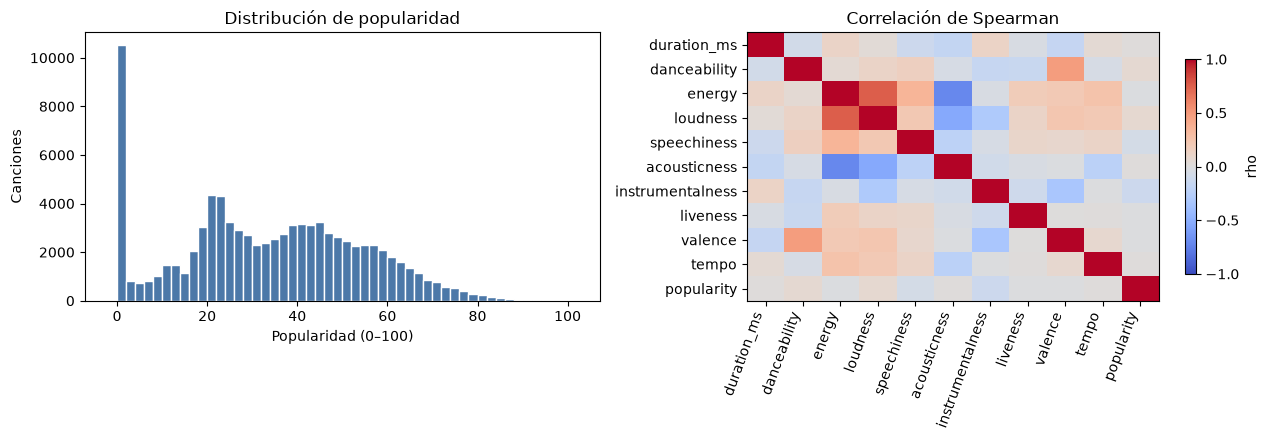

,count,mean,std,min,25%,50%,75%,max
duration_ms,89740.0,229144.366,112945.780,8586.000,173040.000,213295.500,264293.000,5237295.000
danceability,89740.0,0.562,0.177,0.000,0.450,0.576,0.692,0.985
energy,89740.0,0.634,0.257,0.000,0.457,0.676,0.853,1.000
loudness,89740.0,-8.499,5.222,-49.531,-10.322,-7.185,-5.108,4.532
speechiness,89740.0,0.087,0.113,0.000,0.036,0.049,0.086,0.965
acousticness,89740.0,0.328,0.338,0.000,0.017,0.188,0.625,0.996
instrumentalness,89740.0,0.173,0.324,0.000,0.000,0.000,0.098,1.000
liveness,89740.0,0.217,0.195,0.000,0.098,0.132,0.279,1.000
valence,89740.0,0.469,0.263,0.000,0.249,0.457,0.682,0.995
tempo,89740.0,122.058,30.118,0.000,99.263,122.013,140.077,243.372


In [2]:
eda_summary = data[list(NUMERIC_FEATURES) + ["popularity"]].describe().T
eda_summary.to_csv(PROJECT_PATHS.figures / "ea3" / "06_eda_numeric_summary.csv", encoding="utf-8")
print("Distribución de popularidad:")
display(data["popularity"].describe(percentiles=[.25,.5,.75,.95]).to_frame("valor").round(3))
print("Proporción con popularidad 0 / >=70:", round(data.popularity.eq(0).mean(),4), round(data.popularity.ge(70).mean(),4))
fig, axes = plt.subplots(1,2,figsize=(13,4.5))
axes[0].hist(data.popularity,bins=np.arange(-2,103,2),color="#4c78a8",edgecolor="white")
axes[0].set(title="Distribución de popularidad",xlabel="Popularidad (0–100)",ylabel="Canciones")
correlation=data[list(NUMERIC_FEATURES)+["popularity"]].corr(method="spearman")
image=axes[1].imshow(correlation,cmap="coolwarm",vmin=-1,vmax=1,aspect="auto")
axes[1].set_xticks(range(len(correlation.columns)),correlation.columns,rotation=70,ha="right")
axes[1].set_yticks(range(len(correlation.index)),correlation.index)
axes[1].set_title("Correlación de Spearman")
fig.colorbar(image,ax=axes[1],shrink=.8,label="rho")
fig.tight_layout()
fig.savefig(PROJECT_PATHS.figures/"ea3"/"06_eda_distributions_correlation.png",dpi=160,bbox_inches="tight")
plt.show()
display(eda_summary.round(3))

## 3. Protocolos y particiones

El protocolo aleatorio conserva 20 % como prueba, y subdivide el 80 % restante en ajuste y validación. Los hiperparámetros se eligen solo en validación/CV de entrenamiento. En una segunda evaluación independiente, `GroupShuffleSplit` reserva artistas principales completos; una `GroupKFold` ejecutada después diagnostica el desempeño por artista en el conjunto de entrenamiento aleatorio. Se reportan posibles solapamientos de artistas secundarios. No se mezclan métricas de pruebas distintas.


In [3]:
feature_columns = list(NUMERIC_FEATURES) + list(CATEGORICAL_FEATURES) + ["track_genres"]
indexed = data.set_index("track_id", drop=False)

random_split = split_track_ids(data)
fit_data = indexed.loc[list(random_split.fit_ids)]
validation_data = indexed.loc[list(random_split.validation_ids)]
train_data = indexed.loc[list(random_split.train_ids)]
test_data = indexed.loc[list(random_split.test_ids)]
X_fit, y_fit = fit_data[feature_columns], fit_data["popularity"]
X_validation, y_validation = validation_data[feature_columns], validation_data["popularity"]
X_train, y_train = train_data[feature_columns], train_data["popularity"]
X_test, y_test = test_data[feature_columns], test_data["popularity"]
assert set(random_split.fit_ids) | set(random_split.validation_ids) == set(random_split.train_ids)
assert not set(random_split.train_ids) & set(random_split.test_ids)
assert len(random_split.train_ids) == 71_792 and len(random_split.test_ids) == 17_948

print(f"Partición aleatoria, semilla {SEED}")
print(f"Ajuste: {len(fit_data):,}; validación: {len(validation_data):,}; entrenamiento final: {len(train_data):,}; prueba: {len(test_data):,}")
print(f"Huella de IDs de prueba: {random_split.test_sha256}")
display(pd.DataFrame({"partición": ["ajuste", "validación", "prueba"], "canciones": [len(fit_data), len(validation_data), len(test_data)]}))

Partición aleatoria, semilla 42
Ajuste: 57,433; validación: 14,359; entrenamiento final: 71,792; prueba: 17,948
Huella de IDs de prueba: 7270ff57b6fb81215fba2f834942d194183e3854ccac935a65e5a03f7888b318


,partición,canciones
0,ajuste,57433
1,validación,14359
2,prueba,17948


## 4. Núcleo supervisado común

La referencia predice la mediana del entrenamiento. Ridge regulariza un modelo lineal; el árbol representa reglas no lineales. Para ambos se compara el conjunto completo de predictores con la variante sin géneros. La selección usa únicamente MAE de validación; RMSE y complejidad sirven para desempatar. Los pipelines ajustan codificadores y escalas dentro de cada partición.

In [4]:
ridge_grid = [{"alpha": alpha} for alpha in (0.1, 1.0, 10.0, 100.0)]
tree_grid = [
    {"max_depth": None, "min_samples_leaf": 1},  # referencia: DecisionTreeRegressor por defecto
    *[
        {"max_depth": depth, "min_samples_leaf": leaf}
        for depth in (5, 10, 15)
        for leaf in (20, 100)
    ],
]
parameter_grids = {"Ridge": ridge_grid, "Árbol": tree_grid}


def estimator_for(model_name, parameters):
    if model_name == "Ridge":
        return Ridge(**parameters)
    return DecisionTreeRegressor(random_state=SEED, **parameters)


def complexity_for(model_name, parameters):
    if model_name == "Ridge":
        return -parameters["alpha"]
    depth = parameters["max_depth"]
    return (10**9 if depth is None else depth * 1000) - parameters["min_samples_leaf"]


def pipeline_for(model_name, parameters, *, include_genres=True):
    return model_pipeline(estimator_for(model_name, parameters), include_genres=include_genres)

random_validation_rows = []
for variant, include_genres in (("completo", True), ("sin_géneros", False)):
    for model_name, grid in parameter_grids.items():
        for parameters in grid:
            candidate = pipeline_for(model_name, parameters, include_genres=include_genres)
            candidate.fit(X_fit, y_fit)
            scores = regression_metrics(y_validation, candidate.predict(X_validation))
            random_validation_rows.append({
                "variante": variant,
                "modelo": model_name,
                "parámetros": parameters,
                "complejidad": complexity_for(model_name, parameters),
                **scores,
            })

random_validation = pd.DataFrame(random_validation_rows)
random_selected = (
    random_validation.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["variante", "modelo"], sort=False)
    .head(1)
    .reset_index(drop=True)
)

# Comparar la configuración por defecto con la elegida en la misma validación,
# sin consultar la prueba. El ganador de RF procede de la búsqueda CV de Lucas.
_default_params = {
    "Ridge": {"alpha": 1.0},
    "árbol": {"max_depth": None, "min_samples_leaf": 1},
}
_hyperparameter_rows = []
for _model_key, _default in _default_params.items():
    _model_label = next(
        label for label in random_validation["modelo"].unique()
        if str(label).casefold() == _model_key.casefold()
    )
    _candidates = random_validation.loc[
        random_validation["variante"].eq("completo")
        & random_validation["modelo"].eq(_model_label)
    ]
    _default_mask = _candidates["parámetros"].map(lambda x: x == _default)
    if not _default_mask.any():
        raise ValueError(f"No se encontró la configuración por defecto para {_model_label}: {_default}")
    _default_row = _candidates.loc[_default_mask].iloc[0]
    _selected_row = _candidates.sort_values(["MAE", "RMSE", "complejidad"]).iloc[0]
    _model = str(_model_label)
    for _label, _row in (("por_defecto", _default_row), ("seleccionado", _selected_row)):
        _hyperparameter_rows.append({
            "modelo": _model,
            "configuración": _label,
            "parámetros": _row["parámetros"],
            "MAE_validación": _row["MAE"],
            "RMSE_validación": _row["RMSE"],
            "R2_validación": _row["R2"],
        })
hyperparameter_comparison = pd.DataFrame(_hyperparameter_rows)
for _model_key in _default_params:
    _mask = hyperparameter_comparison["modelo"].astype(str).str.casefold().eq(_model_key.casefold())
    _default_mae = hyperparameter_comparison.loc[_mask & hyperparameter_comparison["configuración"].eq("por_defecto"), "MAE_validación"].iloc[0]
    _selected_mae = hyperparameter_comparison.loc[_mask & hyperparameter_comparison["configuración"].eq("seleccionado"), "MAE_validación"].iloc[0]
    _improvement = 100 * (_default_mae - _selected_mae) / _default_mae
    hyperparameter_comparison.loc[_mask, "reducción_MAE_vs_defecto_pct"] = _improvement

display(hyperparameter_comparison.round(3))
hyperparameter_path = PROJECT_PATHS.root / "reports" / "figures" / "ea3" / "05_cesar_hyperparameter_validation.csv"
hyperparameter_comparison.to_csv(hyperparameter_path, index=False, encoding="utf-8")
print(f"Comparación de hiperparámetros guardada en: {hyperparameter_path.relative_to(PROJECT_PATHS.root)}")

random_reference_validation = DummyRegressor(strategy="median").fit(X_fit, y_fit)
random_ref_val_metrics = regression_metrics(y_validation, random_reference_validation.predict(X_validation))
print("Referencia en validación:", random_ref_val_metrics)
print("Configuraciones elegidas sin consultar la prueba:")
display(random_selected[["variante", "modelo", "parámetros", "MAE", "RMSE", "R2"]].round(3))

,modelo,configuración,parámetros,MAE_validación,RMSE_validación,R2_validación,reducción_MAE_vs_defecto_pct
0,Ridge,por_defecto,{'alpha': 1.0},11.788,16.430,0.360,0.023
1,Ridge,seleccionado,{'alpha': 0.1},11.786,16.430,0.360,0.023
2,Árbol,por_defecto,"{'max_depth': None, 'min_samples_leaf': 1}",12.353,19.991,0.052,0.000
3,Árbol,seleccionado,"{'max_depth': None, 'min_samples_leaf': 1}",12.353,19.991,0.052,0.000


Comparación de hiperparámetros guardada en: reports\figures\ea3\05_cesar_hyperparameter_validation.csv
Referencia en validación: {'MAE': 17.207535343686885, 'RMSE': 20.535261977137537, 'R2': -7.188898482390904e-05}
Configuraciones elegidas sin consultar la prueba:


,variante,modelo,parámetros,MAE,RMSE,R2
0,completo,Ridge,{'alpha': 0.1},11.786,16.430,0.360
1,completo,Árbol,"{'max_depth': None, 'min_samples_leaf': 1}",12.353,19.991,0.052
2,sin_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",15.627,19.830,0.067
3,sin_géneros,Ridge,{'alpha': 0.1},16.581,20.162,0.036


### Evaluación única en la prueba aleatoria

Tras fijar parámetros en validación, se reajusta cada variante declarada con todo el entrenamiento y se mide una vez en la prueba reservada. La mejora de MAE se expresa respecto de la referencia mediana.

In [5]:
random_reference = DummyRegressor(strategy="median").fit(X_train, y_train)
random_predictions = {"Referencia mediana": random_reference.predict(X_test)}
random_test_rows = [{
    "variante": "referencia", "modelo": "Dummy mediana", "parámetros": "mediana",
    **regression_metrics(y_test, random_predictions["Referencia mediana"]),
}]

for row in random_selected.itertuples(index=False):
    include_genres = row.variante == "completo"
    name = f"{row.modelo} / {row.variante}"
    fitted = pipeline_for(row.modelo, row.parámetros, include_genres=include_genres)
    fitted.fit(X_train, y_train)
    random_predictions[name] = fitted.predict(X_test)
    random_test_rows.append({
        "variante": row.variante, "modelo": row.modelo, "parámetros": row.parámetros,
        **regression_metrics(y_test, random_predictions[name]),
    })

random_test = pd.DataFrame(random_test_rows)
random_baseline_mae = random_test.loc[random_test["modelo"].eq("Dummy mediana"), "MAE"].iloc[0]
random_test["mejora_MAE_puntos"] = random_baseline_mae - random_test["MAE"]
random_test["mejora_MAE_pct"] = 100 * random_test["mejora_MAE_puntos"] / random_baseline_mae
random_test = random_test.sort_values(["MAE", "RMSE"]).reset_index(drop=True)
display(random_test.round(3))

best_random = random_selected.sort_values(["MAE", "RMSE", "complejidad"]).iloc[0]
random_candidate_name = f"{best_random['modelo']} / {best_random['variante']}"
random_candidate_predictions = random_predictions[random_candidate_name]
random_kpi = top_decile_kpi(test_data["track_id"], y_test, random_candidate_predictions)
print("Candidato fijado en validación:", random_candidate_name)
print("KPI retrospectivo del 10 % superior:", random_kpi)

,variante,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
0,completo,Ridge,{'alpha': 0.1},11.915,16.643,0.348,5.335,30.929
1,completo,Árbol,"{'max_depth': None, 'min_samples_leaf': 1}",12.012,19.572,0.098,5.238,30.368
2,sin_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",15.693,19.834,0.074,1.557,9.026
3,sin_géneros,Ridge,{'alpha': 0.1},16.671,20.223,0.037,0.580,3.360
4,referencia,Dummy mediana,mediana,17.250,20.612,-0.000,0.000,0.000


Candidato fijado en validación: Ridge / completo
KPI retrospectivo del 10 % superior: {'seleccionadas': 1795, 'populares_en_seleccion': 159, 'populares_en_prueba': 653, 'prevalencia': 0.03638288388678404, 'precision': 0.08857938718662953, 'recall': 0.2434915773353752, 'lift': 2.434644473546136}


## 5. Aporte de Ignacio: duración y escalado robusto

Se reproduce el diseño factorial 2×2: tratamiento estándar, `log1p(duration_ms)`, escalado robusto y combinación. Las transformaciones viven dentro del pipeline. Cada tratamiento elige Ridge y árbol con la misma validación aleatoria y usa la prueba compartida solo para cuantificar el desempeño final.

In [6]:
treatments = {
    "estándar": (False, "standard"),
    "log_duración": (True, "standard"),
    "robusto": (False, "robust"),
    "log_duración_robusto": (True, "robust"),
}


def treatment_pipeline(estimator, treatment):
    log_duration, scaler_name = treatments[treatment]
    scaler_factory = RobustScaler if scaler_name == "robust" else StandardScaler
    transformers = []
    if log_duration:
        transformers.extend([
            ("duration", Pipeline([
                ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("scale", scaler_factory()),
            ]), ["duration_ms"]),
            ("numeric", scaler_factory(), [column for column in NUMERIC_FEATURES if column != "duration_ms"]),
        ])
    else:
        transformers.append(("numeric", scaler_factory(), list(NUMERIC_FEATURES)))
    transformers.extend([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), list(CATEGORICAL_FEATURES)),
        ("genres", GenreBinarizer(), ["track_genres"]),
    ])
    preprocessing = ColumnTransformer(transformers, remainder="drop", sparse_threshold=1.0)
    return Pipeline([("preprocessing", preprocessing), ("model", estimator)])

sensitivity_validation_rows = []
for treatment in treatments:
    for model_name, grid in parameter_grids.items():
        for parameters in grid:
            model = treatment_pipeline(estimator_for(model_name, parameters), treatment)
            model.fit(X_fit, y_fit)
            scores = regression_metrics(y_validation, model.predict(X_validation))
            sensitivity_validation_rows.append({
                "tratamiento": treatment,
                "modelo": model_name,
                "parámetros": parameters,
                "complejidad": complexity_for(model_name, parameters),
                **scores,
            })

sensitivity_validation = pd.DataFrame(sensitivity_validation_rows)
sensitivity_selected = (
    sensitivity_validation.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["tratamiento", "modelo"], sort=False)
    .head(1)
    .reset_index(drop=True)
)
display(sensitivity_selected[["tratamiento", "modelo", "parámetros", "MAE", "RMSE", "R2"]].round(3))

sensitivity_rows = []
for row in sensitivity_selected.itertuples(index=False):
    model = treatment_pipeline(estimator_for(row.modelo, row.parámetros), row.tratamiento)
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    scores = regression_metrics(y_test, prediction)
    sensitivity_rows.append({"tratamiento": row.tratamiento, "modelo": row.modelo, **scores})
sensitivity_test = pd.DataFrame(sensitivity_rows)
display(sensitivity_test.sort_values(["tratamiento", "MAE"]).round(3))

,tratamiento,modelo,parámetros,MAE,RMSE,R2
0,estándar,Ridge,{'alpha': 0.1},11.786,16.430,0.360
1,robusto,Ridge,{'alpha': 0.1},11.786,16.430,0.360
2,log_duración,Ridge,{'alpha': 0.1},11.788,16.430,0.360
3,log_duración_robusto,Ridge,{'alpha': 0.1},11.788,16.430,0.360
4,robusto,Árbol,"{'max_depth': None, 'min_samples_leaf': 1}",12.314,19.985,0.053
5,log_duración_robusto,Árbol,"{'max_depth': None, 'min_samples_leaf': 1}",12.317,19.987,0.053
6,estándar,Árbol,"{'max_depth': None, 'min_samples_leaf': 1}",12.353,19.991,0.052
7,log_duración,Árbol,"{'max_depth': None, 'min_samples_leaf': 1}",12.365,20.006,0.051


,tratamiento,modelo,MAE,RMSE,R2
0,estándar,Ridge,11.915,16.643,0.348
6,estándar,Árbol,12.012,19.572,0.098
2,log_duración,Ridge,11.914,16.643,0.348
7,log_duración,Árbol,12.011,19.572,0.098
3,log_duración_robusto,Ridge,11.914,16.643,0.348
5,log_duración_robusto,Árbol,12.074,19.677,0.088
1,robusto,Ridge,11.915,16.643,0.348
4,robusto,Árbol,12.075,19.678,0.088


## 6. Errores por popularidad, contenido explícito y género

Se diagnostica el candidato escogido en validación. Los rangos se fijaron antes de mirar los errores. Para género se expanden las etiquetas después de predecir; una canción puede aparecer en varios grupos, por lo que se informa el soporte por canciones únicas.

In [7]:
error_frame = pd.DataFrame({
    "track_id": test_data["track_id"].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicho": random_candidate_predictions,
    "explicit": test_data["explicit"].to_numpy(),
    "track_genres": test_data["track_genres"].to_numpy(),
})
error_frame["error_abs"] = (error_frame["actual"] - error_frame["predicho"]).abs()
error_frame["sesgo"] = error_frame["predicho"] - error_frame["actual"]
error_frame["error_sq"] = np.square(error_frame["actual"] - error_frame["predicho"])
error_frame["rango"] = np.select(
    [
        error_frame["actual"].eq(0),
        error_frame["actual"].between(0, 35, inclusive="neither"),
        error_frame["actual"].between(35, 70, inclusive="left"),
        error_frame["actual"].ge(70),
    ],
    ["0", "(0,35)", "[35,70)", "[70,100]"],
    default="sin_clasificar",
)
range_metrics = error_frame.groupby("rango", sort=False).agg(
    canciones=("track_id", "nunique"), MAE=("error_abs", "mean"), sesgo_medio=("sesgo", "mean")
).round(3)
display(range_metrics)

explicit_metrics = error_frame.groupby("explicit", sort=True).agg(
    canciones=("track_id", "nunique"), MAE=("error_abs", "mean"),
    RMSE=("error_sq", lambda values: float(np.sqrt(values.mean()))),
    sesgo_medio=("sesgo", "mean"),
    populares_ge_70=("actual", lambda values: int(values.ge(70).sum())),
).round(3)
display(explicit_metrics)

genre_frame = error_frame.assign(genero=error_frame["track_genres"].str.split("|")).explode("genero")
genre_frame = genre_frame.loc[genre_frame["genero"].notna()]
genre_metrics = genre_frame.groupby("genero").agg(
    canciones=("track_id", "nunique"), MAE=("error_abs", "mean"),
    populares_ge_70=("actual", lambda x: int(x.ge(70).sum())),
).query("canciones >= 100").sort_values(["MAE", "canciones"], ascending=[False, False]).round(3)
print(f"Géneros que cumplen soporte mínimo de 100: {len(genre_metrics)}")
display(genre_metrics)

,canciones,MAE,sesgo_medio
rango,,,
"(0,35)",7361,8.040,6.344
"[35,70)",8071,10.546,-8.607
0,1863,24.448,24.148
"[70,100]",653,36.759,-36.759


,canciones,MAE,RMSE,sesgo_medio,populares_ge_70
explicit,,,,,
False,16431,11.704,16.392,-0.120,543
True,1517,14.198,19.153,0.117,110


Géneros que cumplen soporte mínimo de 100: 114


,canciones,MAE,populares_ge_70
genero,,,
electro,223,32.532,59
dance,182,32.175,47
house,206,31.551,52
edm,197,29.726,46
alternative,199,28.757,36
...,...,...,...
forro,206,3.212,0
grindcore,212,3.191,0
sertanejo,207,3.180,0


## 7. Generalización a artistas principales no vistos

La prueba agrupada usa otra semilla reproducible y un `GroupShuffleSplit` por primer artista de `artists`. No existe solapamiento de artistas principales entre entrenamiento y prueba. Se seleccionan parámetros con la validación agrupada propia, se vuelve a ajustar sobre el entrenamiento agrupado completo y se evalúa en su prueba una sola vez. También se cuentan colaboraciones secundarias que cruzan la partición.

In [8]:
artist_split = split_primary_artist_ids(data)
artist_fit = indexed.loc[list(artist_split.fit_ids)]
artist_validation = indexed.loc[list(artist_split.validation_ids)]
artist_train = indexed.loc[list(artist_split.train_ids)]
artist_test = indexed.loc[list(artist_split.test_ids)]
X_artist_fit, y_artist_fit = artist_fit[feature_columns], artist_fit["popularity"]
X_artist_val, y_artist_val = artist_validation[feature_columns], artist_validation["popularity"]
X_artist_train, y_artist_train = artist_train[feature_columns], artist_train["popularity"]
X_artist_test, y_artist_test = artist_test[feature_columns], artist_test["popularity"]


def primary_set(frame):
    return set(frame["artists"].map(primary_artist))


def secondary_set(frame):
    return {
        name.strip().casefold()
        for value in frame["artists"]
        for name in str(value).split(";")[1:]
        if name.strip()
    }

assert not primary_set(artist_train) & primary_set(artist_test)
assert not primary_set(artist_fit) & primary_set(artist_validation)
secondary_overlap = secondary_set(artist_train) & secondary_set(artist_test)
secondary_test_any_overlap = secondary_set(artist_test) & (
    secondary_set(artist_train) | primary_set(artist_train)
)
shared_secondary_tracks = sum(
    bool({name.strip().casefold() for name in str(value).split(";")[1:] if name.strip()} & secondary_test_any_overlap)
    for value in artist_test["artists"]
)
print(f"Ajuste/validación/entrenamiento/prueba: {len(artist_fit):,} / {len(artist_validation):,} / {len(artist_train):,} / {len(artist_test):,}")
print(f"Artistas principales entrenamiento/prueba: {len(primary_set(artist_train)):,} / {len(primary_set(artist_test)):,}")
print(f"Artistas principales compartidos: {len(primary_set(artist_train) & primary_set(artist_test))}")
print(f"Artistas secundarios presentes en ambas particiones: {len(secondary_overlap):,}")
print(f"Canciones de prueba con colaboradores secundarios que aparecen en entrenamiento: {shared_secondary_tracks:,} de {len(artist_test):,}")
print(f"Huella de IDs de prueba agrupada: {artist_split.test_sha256}")

artist_reference_validation = DummyRegressor(strategy="median").fit(X_artist_fit, y_artist_fit)
artist_ref_val = regression_metrics(y_artist_val, artist_reference_validation.predict(X_artist_val))
artist_validation_rows = []
for model_name, grid in parameter_grids.items():
    for parameters in grid:
        model = pipeline_for(model_name, parameters, include_genres=True)
        model.fit(X_artist_fit, y_artist_fit)
        scores = regression_metrics(y_artist_val, model.predict(X_artist_val))
        artist_validation_rows.append({
            "modelo": model_name, "parámetros": parameters,
            "complejidad": complexity_for(model_name, parameters), **scores,
        })
artist_validation_scores = pd.DataFrame(artist_validation_rows)
artist_selected = artist_validation_scores.sort_values(
    ["MAE", "RMSE", "complejidad"]
).groupby("modelo", sort=False).head(1).reset_index(drop=True)
print("Referencia en validación agrupada:", artist_ref_val)
display(artist_selected[["modelo", "parámetros", "MAE", "RMSE", "R2"]].round(3))

artist_reference = DummyRegressor(strategy="median").fit(X_artist_train, y_artist_train)
artist_predictions = {"Dummy mediana": artist_reference.predict(X_artist_test)}
artist_test_rows = [{"modelo": "Dummy mediana", "parámetros": "mediana", **regression_metrics(y_artist_test, artist_predictions["Dummy mediana"])}]
for row in artist_selected.itertuples(index=False):
    model = pipeline_for(row.modelo, row.parámetros, include_genres=True)
    model.fit(X_artist_train, y_artist_train)
    artist_predictions[row.modelo] = model.predict(X_artist_test)
    artist_test_rows.append({"modelo": row.modelo, "parámetros": row.parámetros, **regression_metrics(y_artist_test, artist_predictions[row.modelo])})
artist_test_scores = pd.DataFrame(artist_test_rows)
artist_baseline_mae = artist_test_scores.loc[artist_test_scores["modelo"].eq("Dummy mediana"), "MAE"].iloc[0]
artist_test_scores["mejora_MAE_puntos"] = artist_baseline_mae - artist_test_scores["MAE"]
artist_test_scores["mejora_MAE_pct"] = 100 * artist_test_scores["mejora_MAE_puntos"] / artist_baseline_mae
display(artist_test_scores.round(3))

Ajuste/validación/entrenamiento/prueba: 57,176 / 14,371 / 71,547 / 18,193
Artistas principales entrenamiento/prueba: 14,111 / 3,528
Artistas principales compartidos: 0
Artistas secundarios presentes en ambas particiones: 1,415
Canciones de prueba con colaboradores secundarios que aparecen en entrenamiento: 2,633 de 18,193
Huella de IDs de prueba agrupada: a76b54b8e2fd914db9dc5984ff77a8ac07e5b13bf0f36b7e371d048194e5ac52


Referencia en validación agrupada: {'MAE': 17.423456961937234, 'RMSE': 20.750497251319622, 'R2': -0.0013008562675349555}


,modelo,parámetros,MAE,RMSE,R2
0,Ridge,{'alpha': 0.1},12.297,17.342,0.301
1,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14.603,18.580,0.197


,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
0,Dummy mediana,mediana,16.707,20.075,-0.003,0.000,0.000
1,Ridge,{'alpha': 0.1},12.102,16.740,0.302,4.605,27.564
2,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14.455,18.247,0.171,2.252,13.479


## 8. K-Means, perfiles y PCA

K-Means usa las diez variables numéricas escaladas del entrenamiento aleatorio. No incluye `popularity`, identificadores, nombres ni géneros. La selección de K considera la silueta en una muestra fija, el codo de inercia y que el grupo más pequeño cubra al menos 1 % del entrenamiento. Popularidad se agrega después solo como descriptor.

,K,inercia,silueta_muestra,grupo_mínimo_pct
0,2,577883.661,0.245,24.767
1,3,519168.980,0.149,21.412
2,4,474263.881,0.152,7.817
3,5,434429.626,0.168,1.227
4,6,399967.676,0.166,1.209
5,7,369639.701,0.169,1.170
6,8,352524.864,0.176,0.043


K elegido: 2


,canciones,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularidad_mediana
cluster,,,,,,,,,,,,
0,54011,217053.0,0.607,0.762,-6.140,0.055,0.078,0.000,0.145,0.527,125.000,34.0
1,17781,198560.0,0.468,0.295,-13.033,0.039,0.828,0.004,0.116,0.265,107.736,29.0


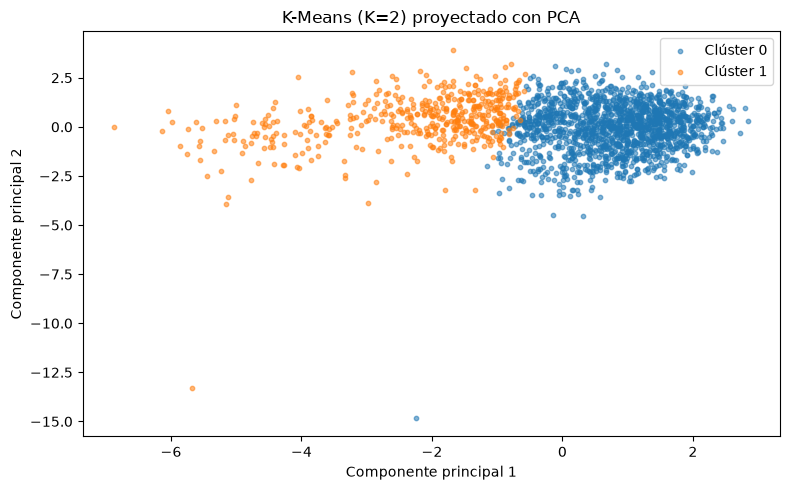

PCA conserva 44.1% de varianza en dos dimensiones (28.9% + 15.2%).
La proyección sirve para visualizar; K-Means se ajustó sobre las diez variables escaladas.


In [9]:
cluster_scaler = StandardScaler().fit(train_data[list(NUMERIC_FEATURES)])
cluster_features = cluster_scaler.transform(train_data[list(NUMERIC_FEATURES)])
sample_indices = np.random.default_rng(SEED).choice(len(train_data), size=min(2_000, len(train_data)), replace=False)
cluster_rows, cluster_fits = [], {}
for k in range(2, 9):
    fitted = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(cluster_features)
    cluster_fits[k] = fitted
    sample_labels = fitted.labels_[sample_indices]
    cluster_rows.append({
        "K": k, "inercia": fitted.inertia_,
        "silueta_muestra": silhouette_score(cluster_features[sample_indices], sample_labels),
        "grupo_mínimo_pct": 100 * np.bincount(fitted.labels_).min() / len(train_data),
    })
cluster_evidence = pd.DataFrame(cluster_rows)
display(cluster_evidence.round(3))
eligible = cluster_evidence.loc[cluster_evidence["grupo_mínimo_pct"].ge(1)]
chosen_k = int(eligible.sort_values(["silueta_muestra", "K"], ascending=[False, True]).iloc[0]["K"])
chosen_clustering = cluster_fits[chosen_k]
profile_frame = train_data[list(NUMERIC_FEATURES) + ["popularity"]].copy()
profile_frame["cluster"] = chosen_clustering.labels_
cluster_profile = profile_frame.groupby("cluster").agg(
    canciones=("popularity", "size"),
    **{column: (column, "median") for column in NUMERIC_FEATURES},
    popularidad_mediana=("popularity", "median"),
).round(3)
print(f"K elegido: {chosen_k}")
display(cluster_profile)

pca = PCA(n_components=2, random_state=SEED).fit(cluster_features)
projection = pca.transform(cluster_features[sample_indices])
fig, ax = plt.subplots(figsize=(8, 5))
for cluster_id in range(chosen_k):
    mask = chosen_clustering.labels_[sample_indices] == cluster_id
    ax.scatter(projection[mask, 0], projection[mask, 1], s=10, alpha=0.55, label=f"Clúster {cluster_id}")
ax.set(xlabel="Componente principal 1", ylabel="Componente principal 2", title=f"K-Means (K={chosen_k}) proyectado con PCA")
ax.legend()
fig.tight_layout()
figure_dir = PROJECT_PATHS.figures / "ea2"
figure_dir.mkdir(parents=True, exist_ok=True)
cluster_figure_path = figure_dir / "05_clusters_pca.png"
fig.savefig(cluster_figure_path, dpi=160, bbox_inches="tight")
plt.show()
explained = pca.explained_variance_ratio_
print(f"PCA conserva {explained.sum():.1%} de varianza en dos dimensiones ({explained[0]:.1%} + {explained[1]:.1%}).")
print("La proyección sirve para visualizar; K-Means se ajustó sobre las diez variables escaladas.")

### Sensibilidad de los clústeres

Se conserva K y se repite el ajuste, por separado, tras transformar la duración con `log1p` y al retirar `loudness`. ARI compara asignaciones con la solución original sin depender de los nombres de los clústeres.

In [10]:
original_numeric = train_data[list(NUMERIC_FEATURES)]
duration_log = original_numeric.copy()
duration_log["duration_ms"] = np.log1p(duration_log["duration_ms"])
without_loudness = original_numeric.drop(columns="loudness")
stability_rows = []
for label, values in (("original", original_numeric), ("duración_log1p", duration_log), ("sin_loudness", without_loudness)):
    scaled = cluster_features if label == "original" else StandardScaler().fit_transform(values)
    labels = chosen_clustering.labels_ if label == "original" else KMeans(
        n_clusters=chosen_k, random_state=SEED, n_init=10
    ).fit_predict(scaled)
    stability_rows.append({
        "variante": label, "variables": values.shape[1],
        "silueta_muestra": silhouette_score(scaled[sample_indices], labels[sample_indices]),
        "ARI_vs_original": adjusted_rand_score(chosen_clustering.labels_, labels),
        "grupo_0": int(np.sum(labels == 0)), "grupo_1": int(np.sum(labels == 1)),
    })
stability = pd.DataFrame(stability_rows)
display(stability.round(3))

,variante,variables,silueta_muestra,ARI_vs_original,grupo_0,grupo_1
0,original,10,0.245,1.000,54011,17781
1,duración_log1p,10,0.241,0.968,53954,17838
2,sin_loudness,9,0.209,0.807,51769,20023


## 9. Comparación integrada y conclusiones

La tabla final pone la prueba aleatoria y la prueba agrupada en sus propios contextos; no se deben comparar como si fueran las mismas canciones. Un MAE menor que Dummy muestra señal predictiva en esta muestra, pero no acredita utilidad comercial ni predicción de éxito futuro. La prueba aleatoria puede compartir artistas; la prueba agrupada excluye artistas principales, aunque las colaboraciones secundarias se superponen.

In [11]:
random_summary = random_test[["variante", "modelo", "MAE", "RMSE", "R2", "mejora_MAE_pct"]].copy()
random_summary.insert(0, "partición", "aleatoria")
artist_summary = artist_test_scores[["modelo", "MAE", "RMSE", "R2", "mejora_MAE_pct"]].copy()
artist_summary.insert(0, "variante", "completo")
artist_summary.insert(0, "partición", "por artista principal")
combined_results = pd.concat([random_summary, artist_summary], ignore_index=True)
display(combined_results.round(3))

print(f"MAE Ridge completo, aleatorio: {random_summary.loc[random_summary['modelo'].eq('Ridge') & random_summary['variante'].eq('completo'), 'MAE'].iloc[0]:.3f}")
print(f"MAE de Dummy, aleatorio: {random_summary.loc[random_summary['modelo'].eq('Dummy mediana'), 'MAE'].iloc[0]:.3f}")
print(f"KPI Ridge en prueba aleatoria: precisión {random_kpi['precision']:.1%}, recall {random_kpi['recall']:.1%}, lift {random_kpi['lift']:.3f}")
print(f"Clústeres seleccionados: K={chosen_k}; PCA 2D: {explained.sum():.1%} de varianza explicada")

# Guardar tablas reproducibles que pueden consumirse en informes y diapositivas.
summary_path = figure_dir / "05_model_comparison_results.csv"
combined_results.to_csv(summary_path, index=False, encoding="utf-8")
print(f"Tabla guardada en: {summary_path.relative_to(PROJECT_PATHS.root)}")

,partición,variante,modelo,MAE,RMSE,R2,mejora_MAE_pct
0,aleatoria,completo,Ridge,11.915,16.643,0.348,30.929
1,aleatoria,completo,Árbol,12.012,19.572,0.098,30.368
2,aleatoria,sin_géneros,Árbol,15.693,19.834,0.074,9.026
3,aleatoria,sin_géneros,Ridge,16.671,20.223,0.037,3.360
4,aleatoria,referencia,Dummy mediana,17.250,20.612,-0.000,0.000
5,por artista principal,completo,Dummy mediana,16.707,20.075,-0.003,0.000
6,por artista principal,completo,Ridge,12.102,16.740,0.302,27.564
7,por artista principal,completo,Árbol,14.455,18.247,0.171,13.479


MAE Ridge completo, aleatorio: 11.915
MAE de Dummy, aleatorio: 17.250
KPI Ridge en prueba aleatoria: precisión 8.9%, recall 24.3%, lift 2.435
Clústeres seleccionados: K=2; PCA 2D: 44.1% de varianza explicada
Tabla guardada en: reports\figures\ea2\05_model_comparison_results.csv


### Lectura para el equipo

- En la prueba aleatoria, el Ridge completo reduce el MAE frente a Dummy; el árbol mejora la referencia, aunque queda por detrás de Ridge.
- Añadir géneros aporta gran parte de la mejora observada en Ridge. La transformación de duración y el escalado robusto producen diferencias pequeñas frente al tratamiento estándar.
- Al reservar artistas principales, Ridge sigue mejor que la referencia, con métricas propias de esa partición. La superposición de colaboradores secundarios impide describirla como prueba de artistas completamente desconocidos.
- El ranking retrospectivo del 10 % mejora sobre una selección aleatoria en la prueba, pero no prueba eficacia comercial. La popularidad ya está presente en la fuente como objetivo histórico.
- K-Means entrega perfiles exploratorios. Dos componentes PCA explican 44,1 % de la varianza: la visualización pierde el resto de la información.
- La fuente está balanceada artificialmente por género y no contiene fecha de lanzamiento, región, playlists ni exposición promocional. No hay evaluación temporal, causal ni de lanzamientos futuros.

## 10. IE9–IE12 · búsqueda real, comparación final y validación por artista

Esta sección ejecuta desde cero la comparación de Dummy, Ridge, árbol y Random Forest. La búsqueda de bosque explora 12 de 144 combinaciones con 3 folds aleatorios, seleccionando por MAE. Toda la transformación está en el pipeline y cada proceso usa un solo trabajador para limitar memoria. Luego se mide una vez en la prueba aleatoria ya declarada y se calcula el KPI retrospectivo. Finalmente se ejecuta GroupKFold por artista principal dentro del entrenamiento; la prueba aleatoria no participa en esa validación.

El candidato ganador de RF se determina sin consultar resultados de prueba. La comparación aleatoria mide generalización entre canciones, no entre artistas. GroupKFold reevalúa los modelos con hiperparámetros congelados; como RF se eligió mediante CV aleatoria, su GroupKFold es un diagnóstico condicionado y no una selección anidada imparcial.


In [12]:
from time import perf_counter
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, KFold, RandomizedSearchCV, cross_validate
from spotify_popularity.modeling.validation import validation_plan

scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
cv_random = KFold(n_splits=3, shuffle=True, random_state=SEED)
models_cv = {
    "Dummy mediana": DummyRegressor(strategy="median"),
    "Ridge": model_pipeline(Ridge(alpha=0.1)),
    "Árbol": model_pipeline(DecisionTreeRegressor(max_depth=15, min_samples_leaf=20, random_state=SEED)),
}
random_cv_rows = []
for name, estimator in models_cv.items():
    started = perf_counter()
    scores = cross_validate(
        estimator, X_train, y_train, cv=cv_random, scoring=scoring,
        return_train_score=True, n_jobs=1, pre_dispatch=1, error_score="raise",
    )
    random_cv_rows.append({
        "modelo": name,
        "MAE_CV": -scores["test_MAE"].mean(),
        "MAE_CV_sd": scores["test_MAE"].std(ddof=0),
        "RMSE_CV": -scores["test_RMSE"].mean(),
        "RMSE_CV_sd": scores["test_RMSE"].std(ddof=0),
        "R2_CV": scores["test_R2"].mean(),
        "R2_CV_sd": scores["test_R2"].std(ddof=0),
        "MAE_train_CV": -scores["train_MAE"].mean(),
        "segundos": perf_counter() - started,
    })
random_cv_results = pd.DataFrame(random_cv_rows)
display(random_cv_results.round(4))

rf_space = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 15, 25, None],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": ["sqrt", 0.5, 1.0],
}
rf_pipeline = model_pipeline(RandomForestRegressor(random_state=SEED, n_jobs=1))
rf_search = RandomizedSearchCV(
    rf_pipeline, rf_space, n_iter=12, cv=cv_random, scoring=scoring,
    refit="MAE", random_state=SEED, n_jobs=4, pre_dispatch=4,
    return_train_score=True, error_score="raise",
)
rf_started = perf_counter()
rf_search.fit(X_train, y_train)
rf_search_seconds = perf_counter() - rf_started
rf_search_table = pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_MAE").copy()
for metric in ("MAE", "RMSE"):
    rf_search_table[f"mean_test_{metric}"] *= -1
    rf_search_table.rename(columns={f"mean_test_{metric}": f"{metric}_CV"}, inplace=True)
rf_search_table.rename(columns={
    "rank_test_MAE":"rango_MAE", "params":"parámetros", "std_test_MAE":"MAE_CV_sd",
    "std_test_RMSE":"RMSE_CV_sd", "mean_test_R2":"R2_CV", "std_test_R2":"R2_CV_sd",
    "mean_train_MAE":"MAE_train_CV", "mean_fit_time":"fit_seconds_mean",
}, inplace=True)
# sklearn stores every scorer as a negated score; convert train MAE back to positive points.
rf_search_table["MAE_train_CV"] *= -1
search_columns = ["rango_MAE", "parámetros", "MAE_CV", "MAE_CV_sd", "RMSE_CV", "RMSE_CV_sd", "R2_CV", "R2_CV_sd", "MAE_train_CV", "fit_seconds_mean"]
rf_search_table[search_columns].to_csv(PROJECT_PATHS.figures / "ea3" / "06_rf_search.csv", index=False, encoding="utf-8")
print(f"RandomizedSearchCV finalizada en {rf_search_seconds/60:.1f} min.")
print("Mejores parámetros (selección exclusivamente por CV de entrenamiento):", rf_search.best_params_)
print(f"MAE CV ganador: {-rf_search.best_score_:.4f}")
display(rf_search_table[search_columns].round(4))


,modelo,MAE_CV,MAE_CV_sd,RMSE_CV,RMSE_CV_sd,R2_CV,R2_CV_sd,MAE_train_CV,segundos
0,Dummy mediana,17.2242,0.0262,20.5702,0.0269,-0.0001,0.0001,17.2242,0.1070
1,Ridge,11.8185,0.0448,16.5206,0.0693,0.3549,0.0049,11.7816,2.1858
2,Árbol,14.3816,0.0174,18.3193,0.0290,0.2068,0.0009,14.2354,3.9615


RandomizedSearchCV finalizada en 71.8 min.
Mejores parámetros (selección exclusivamente por CV de entrenamiento): {'model__n_estimators': 100, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': None}
MAE CV ganador: 9.9005


,rango_MAE,parámetros,MAE_CV,MAE_CV_sd,RMSE_CV,RMSE_CV_sd,R2_CV,R2_CV_sd,MAE_train_CV,fit_seconds_mean
6,1,"{'model__n_estimators': 100, 'model__min_sampl...",9.9005,0.0176,14.7681,0.0388,0.4845,0.0031,3.7674,1554.0036
0,2,"{'model__n_estimators': 100, 'model__min_sampl...",11.6705,0.0373,15.8198,0.0626,0.4085,0.0044,10.7959,52.5371
3,3,"{'model__n_estimators': 200, 'model__min_sampl...",12.8076,0.0278,16.9843,0.0507,0.3182,0.0028,11.7457,524.8069
11,4,"{'model__n_estimators': 100, 'model__min_sampl...",13.1245,0.0630,16.8612,0.0682,0.3281,0.0039,12.6869,22.5080
2,5,"{'model__n_estimators': 200, 'model__min_sampl...",13.2293,0.0460,16.9571,0.0521,0.3204,0.0026,12.9393,38.8293
10,6,"{'model__n_estimators': 100, 'model__min_sampl...",14.0223,0.0163,17.8111,0.0662,0.2502,0.0049,13.6559,55.9606
4,7,"{'model__n_estimators': 300, 'model__min_sampl...",14.0518,0.0058,17.8252,0.0444,0.2490,0.0036,13.7801,148.8104
7,8,"{'model__n_estimators': 300, 'model__min_sampl...",14.1525,0.0180,18.0024,0.0324,0.2340,0.0035,13.8164,302.3515
8,9,"{'model__n_estimators': 100, 'model__min_sampl...",14.1714,0.0248,18.0143,0.0629,0.2330,0.0059,13.9108,92.6130
5,10,"{'model__n_estimators': 100, 'model__min_sampl...",14.8681,0.0151,18.4184,0.0590,0.1982,0.0043,14.7179,33.7267


### 9.1 Evaluación aleatoria final y KPI retrospectivo

Se reajustan los candidatos congelados con todo el entrenamiento aleatorio. El bosque ganador ya se reajusta sobre ese entrenamiento mediante `refit=True`. La prueba se consulta solo en esta evaluación final. El KPI del decil superior evalúa recuperación histórica de canciones con `popularity ≥ 70`, no una clasificación prospectiva ni accuracy.


,modelo,MAE,RMSE,R2,mejora_vs_Dummy_pct
0,Dummy mediana,17.2501,20.6116,-0.0004,0.0000
1,Ridge,11.9147,16.6434,0.3477,30.9293
2,Árbol,14.5076,18.4597,0.1976,15.8983
3,Random Forest,9.6479,14.5365,0.5024,44.0703


,modelo,seleccionadas,populares_en_seleccion,populares_en_prueba,prevalencia,precision,recall,lift
0,Dummy mediana,1795,63,653,0.0364,0.0351,0.0965,0.9647
1,Ridge,1795,159,653,0.0364,0.0886,0.2435,2.4346
2,Árbol,1795,119,653,0.0364,0.0663,0.1822,1.8222
3,Random Forest,1795,237,653,0.0364,0.1320,0.3629,3.6290


,tipo,segmento,canciones,MAE,populares_ge_70
0,popularidad,"(0,35)",7361,7.1867,0
1,popularidad,0,1863,14.1921,0
2,popularidad,"[35,70)",8071,9.0812,0
3,popularidad,"[70,100]",653,31.4316,653
4,explicit,False,16431,9.5456,543
5,explicit,True,1517,10.7557,110


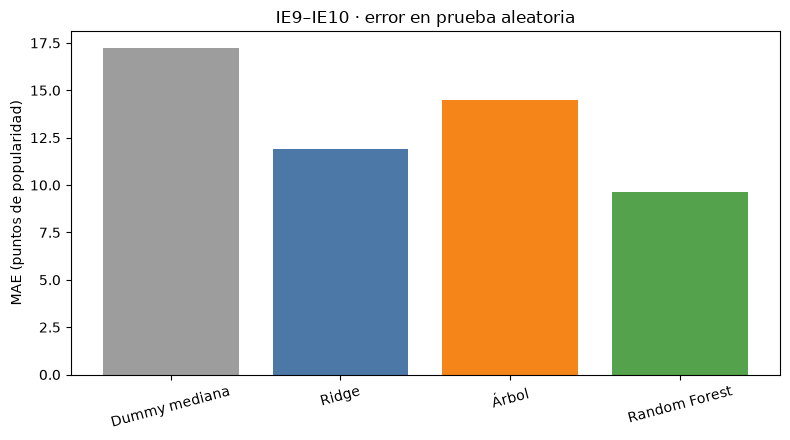

In [13]:
final_models = {
    "Dummy mediana": DummyRegressor(strategy="median"),
    "Ridge": model_pipeline(Ridge(alpha=0.1)),
    "Árbol": model_pipeline(DecisionTreeRegressor(max_depth=15, min_samples_leaf=20, random_state=SEED)),
    "Random Forest": rf_search.best_estimator_,
}
final_predictions = {}
final_rows = []
for name, estimator in final_models.items():
    if name != "Random Forest":
        estimator.fit(X_train, y_train)
    prediction = estimator.predict(X_test)
    final_predictions[name] = prediction
    final_rows.append({"modelo":name, **regression_metrics(y_test, prediction)})
random_ep3_test = pd.DataFrame(final_rows)
dummy_mae = random_ep3_test.loc[random_ep3_test.modelo.eq("Dummy mediana"), "MAE"].iloc[0]
random_ep3_test["mejora_vs_Dummy_pct"] = 100*(dummy_mae-random_ep3_test.MAE)/dummy_mae
random_ep3_test.to_csv(PROJECT_PATHS.figures / "ea3" / "06_random_test.csv", index=False, encoding="utf-8")
display(random_ep3_test.round(4))

kpi_rows=[]
for name,prediction in final_predictions.items():
    kpi_rows.append({"modelo":name, **top_decile_kpi(test_data.track_id, y_test, prediction)})
random_kpi_table=pd.DataFrame(kpi_rows)
random_kpi_table.to_csv(PROJECT_PATHS.figures / "ea3" / "06_random_top_decile_kpi.csv", index=False, encoding="utf-8")
display(random_kpi_table.round(4))

rf_diag = pd.DataFrame({"track_id":test_data.track_id.to_numpy(),"actual":y_test.to_numpy(),"predicho":final_predictions["Random Forest"],"explicit":test_data.explicit.to_numpy()})
rf_diag["error_abs"]=(rf_diag.actual-rf_diag.predicho).abs()
rf_diag["rango"]=np.select([rf_diag.actual.eq(0),rf_diag.actual.between(0,35,inclusive="neither"),rf_diag.actual.between(35,70,inclusive="left"),rf_diag.actual.ge(70)],["0","(0,35)","[35,70)","[70,100]"],default="sin_clasificar")
rf_segment_rows=[]
for kind,grouping in (("popularidad","rango"),("explicit","explicit")):
    tab=rf_diag.groupby(grouping).agg(canciones=("track_id","nunique"),MAE=("error_abs","mean"),populares_ge_70=("actual",lambda s:int(s.ge(70).sum()))).reset_index().rename(columns={grouping:"segmento"})
    tab.insert(0,"tipo",kind); rf_segment_rows.append(tab)
rf_segments=pd.concat(rf_segment_rows,ignore_index=True)
rf_segments.to_csv(PROJECT_PATHS.figures / "ea3" / "06_rf_segments.csv",index=False,encoding="utf-8")
display(rf_segments.round(4))

fig,ax=plt.subplots(figsize=(8,4.5))
ax.bar(random_ep3_test.modelo,random_ep3_test.MAE,color=["#9d9d9d","#4c78a8","#f58518","#54a24b"])
ax.set(ylabel="MAE (puntos de popularidad)",title="IE9–IE10 · error en prueba aleatoria")
ax.tick_params(axis="x",rotation=15)
fig.tight_layout()
fig.savefig(PROJECT_PATHS.figures / "ea3" / "06_random_test_mae.png",dpi=160,bbox_inches="tight")
plt.show()


### 9.2 Validación cruzada agrupada por artista principal

`GroupKFold` se aplica solo a las 71.792 canciones de entrenamiento de la partición aleatoria. Cada fold mantiene separado el artista principal. Se registran métricas en validación, brecha MAE entrenamiento–validación, tiempos y presencia de colaboradores secundarios compartidos. Ninguna fila de la prueba aleatoria ingresa a estos ajustes.


In [14]:
group_folds, group_audit, group_assignments = validation_plan(train_data.reset_index(drop=True), random_split.test_ids, n_splits=3)
group_folds = [fold for fold in group_folds if fold.strategy == "GroupKFold"]
assert len(group_folds)==3
assert group_audit.loc[group_audit.estrategia.eq("GroupKFold"),"principales_compartidos"].eq(0).all()
assert group_audit.prueba_ids_en_fold.eq(0).all()
group_candidates = {
    "Dummy mediana": final_models["Dummy mediana"],
    "Ridge": final_models["Ridge"],
    "Árbol": final_models["Árbol"],
    "Random Forest": final_models["Random Forest"],
}
feature_cols = list(NUMERIC_FEATURES)+list(CATEGORICAL_FEATURES)+["track_genres"]
group_rows=[]
for model_name,estimator in group_candidates.items():
    for fold in group_folds:
        fit=train_data.reset_index(drop=True).iloc[fold.fit]
        valid=train_data.reset_index(drop=True).iloc[fold.validation]
        fitted=clone(estimator)
        started=perf_counter(); fitted.fit(fit[feature_cols],fit.popularity); fit_seconds=perf_counter()-started
        pred=fitted.predict(valid[feature_cols]); scores=regression_metrics(valid.popularity,pred)
        train_scores=regression_metrics(fit.popularity,fitted.predict(fit[feature_cols]))
        group_rows.append({"modelo":model_name,"fold":fold.number,**scores,"MAE_train":train_scores["MAE"],"brecha_MAE":scores["MAE"]-train_scores["MAE"],"fit_seconds":fit_seconds})
group_cv=pd.DataFrame(group_rows)
group_cv.to_csv(PROJECT_PATHS.figures / "ea3" / "06_group_cv_folds.csv",index=False,encoding="utf-8")
group_summary=group_cv.groupby("modelo",sort=False).agg(
    folds=("fold","count"),MAE_media=("MAE","mean"),MAE_sd=("MAE",lambda x:x.std(ddof=0)),
    RMSE_media=("RMSE","mean"),RMSE_sd=("RMSE",lambda x:x.std(ddof=0)),
    R2_media=("R2","mean"),R2_sd=("R2",lambda x:x.std(ddof=0)),
    MAE_train_media=("MAE_train","mean"),brecha_MAE_media=("brecha_MAE","mean"),fit_seconds_media=("fit_seconds","mean"),
).reset_index()
group_summary.to_csv(PROJECT_PATHS.figures / "ea3" / "06_group_cv_summary.csv",index=False,encoding="utf-8")
group_audit.to_csv(PROJECT_PATHS.figures / "ea3" / "06_group_cv_audit.csv",index=False,encoding="utf-8")
display(group_audit.loc[group_audit.estrategia.eq("GroupKFold")].round(3))
display(group_cv.round(4))
display(group_summary.round(4))


,estrategia,fold,fit_canciones,validacion_canciones,fit_artistas_principales,validacion_artistas_principales,principales_compartidos,validacion_con_secundario_en_fit,fit_sha256,validacion_sha256,prueba_ids_en_fold
3,GroupKFold,1,47861,23931,10712,5356,0,3032,63eceb5c24090be59c98be94572952ef85e32a64c1ac3c...,97292776ff1b9630983983fed9fce080d77b60a53b7146...,0
4,GroupKFold,2,47861,23931,10712,5356,0,3087,1320444d81b5868f46b5612905237dddbfc5aead567ded...,339bb97ad26960677169c6fa7882df5ef39ef50bfae798...,0
5,GroupKFold,3,47862,23930,10712,5356,0,3093,eb4aa3da5d6f7f06a6b75c0ab224118ac999f829bf193f...,40922dba4129b0cb7f7561de70619511304a60bd0fb880...,0


,modelo,fold,MAE,RMSE,R2,MAE_train,brecha_MAE,fit_seconds
0,Dummy mediana,1,17.0705,20.4870,-0.0001,17.3010,-0.2304,0.0051
1,Dummy mediana,2,17.1834,20.4969,-0.0001,17.2445,-0.0611,0.0049
2,Dummy mediana,3,17.4186,20.7260,-0.0000,17.1270,0.2916,0.0051
3,Ridge,1,11.8588,16.4658,0.3540,11.8600,-0.0011,0.3853
4,Ridge,2,11.6934,16.3332,0.3650,11.9780,-0.2846,0.3599
5,Ridge,3,12.6296,17.7736,0.2646,11.3707,1.2588,0.3649
6,Árbol,1,14.5139,18.4677,0.1873,14.3487,0.1652,1.2601
7,Árbol,2,14.7476,18.5454,0.1813,14.2792,0.4685,1.2233
8,Árbol,3,14.9919,19.0738,0.1531,14.0038,0.9881,1.0740
9,Random Forest,1,11.3759,16.3905,0.3599,3.6750,7.7010,1040.2543


,modelo,folds,MAE_media,MAE_sd,RMSE_media,RMSE_sd,R2_media,R2_sd,MAE_train_media,brecha_MAE_media,fit_seconds_media
0,Dummy mediana,3,17.2242,0.1450,20.5700,0.1104,-0.0001,0.0000,17.2242,0.0000,0.0050
1,Ridge,3,12.0606,0.4079,16.8575,0.6500,0.3278,0.0449,11.7362,0.3244,0.3700
2,Árbol,3,14.7512,0.1951,18.6956,0.2693,0.1739,0.0149,14.2105,0.5406,1.1858
3,Random Forest,3,11.7520,0.4580,16.9686,0.7703,0.3187,0.0550,3.6920,8.0600,1086.0738


## 10. Síntesis, métricas e interpretación

Las cifras se completan a partir de las tablas recién calculadas. `MAE`, `RMSE` y `R²` son métricas de regresión y no accuracy. El KPI del 10 % superior es una evaluación retrospectiva. El valor `popularity ≥ 70` ya se observó en los datos y no significa que el modelo pueda saber qué lanzamientos futuros tendrán éxito.

La fuente está balanceada artificialmente por género, la popularidad es histórica y no hay fechas para evaluar temporalidad. Un mejor puntaje en la partición aleatoria no garantiza generalización a artistas nuevos: para esa pregunta se consulta la partición y la CV agrupadas. La colaboración secundaria puede persistir entre grupos y queda documentada en la auditoría.


In [15]:
import json
# Resultados compactos para el informe y la presentación; cada protocolo conserva su propia tabla.
print("Núcleo aleatorio (Notebook 05), candidato Ridge/árbol fijado por validación:")
display(random_test[["variante","modelo","MAE","RMSE","R2"]].round(4))
print("Comparación EP3 en prueba aleatoria:")
display(random_ep3_test.round(4))
print("Validación GroupKFold por artista principal:")
display(group_summary.round(4))
print(f"PCA 2D conserva {explained.sum():.1%} de la varianza; K-Means se ajustó sobre diez variables escaladas.")
print(f"RF RandomizedSearchCV: {rf_search.n_iter} combinaciones / 144 posibles; duración {rf_search_seconds/60:.1f} min; ganador {rf_search.best_params_}.")
print("Interpretación: resultados retrospectivos; no equivalen a utilidad comercial ni éxito futuro.")

# Huellas y versiones para reproducibilidad.
from spotify_popularity.data.provenance import sha256_file
import platform
manifest={
    "source_sha256":sha256_file(PROJECT_PATHS.raw_dataset),"random_test_sha256":random_split.test_sha256,
    "random_train_tracks":len(train_data),"random_test_tracks":len(test_data),"seed":SEED,
    "python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"sklearn":sklearn.__version__,
    "rf_search_seconds":rf_search_seconds,"rf_search_candidates":rf_search.n_iter,"rf_search_cv_folds":3,
    "group_cv_folds":3,"rf_outer_jobs":4,"rf_n_jobs":1,"clean_kernel":True,
}
manifest_path=PROJECT_PATHS.figures/"ea3"/"06_ep3_manifest.json"
manifest_path.write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print(json.dumps(manifest,ensure_ascii=False,indent=2))


Núcleo aleatorio (Notebook 05), candidato Ridge/árbol fijado por validación:


,variante,modelo,MAE,RMSE,R2
0,completo,Ridge,11.9147,16.6434,0.3477
1,completo,Árbol,12.0116,19.5723,0.0979
2,sin_géneros,Árbol,15.6931,19.8337,0.0737
3,sin_géneros,Ridge,16.6705,20.2229,0.0370
4,referencia,Dummy mediana,17.2501,20.6116,-0.0004


Comparación EP3 en prueba aleatoria:


,modelo,MAE,RMSE,R2,mejora_vs_Dummy_pct
0,Dummy mediana,17.2501,20.6116,-0.0004,0.0000
1,Ridge,11.9147,16.6434,0.3477,30.9293
2,Árbol,14.5076,18.4597,0.1976,15.8983
3,Random Forest,9.6479,14.5365,0.5024,44.0703


Validación GroupKFold por artista principal:


,modelo,folds,MAE_media,MAE_sd,RMSE_media,RMSE_sd,R2_media,R2_sd,MAE_train_media,brecha_MAE_media,fit_seconds_media
0,Dummy mediana,3,17.2242,0.1450,20.5700,0.1104,-0.0001,0.0000,17.2242,0.0000,0.0050
1,Ridge,3,12.0606,0.4079,16.8575,0.6500,0.3278,0.0449,11.7362,0.3244,0.3700
2,Árbol,3,14.7512,0.1951,18.6956,0.2693,0.1739,0.0149,14.2105,0.5406,1.1858
3,Random Forest,3,11.7520,0.4580,16.9686,0.7703,0.3187,0.0550,3.6920,8.0600,1086.0738


PCA 2D conserva 44.1% de la varianza; K-Means se ajustó sobre diez variables escaladas.
RF RandomizedSearchCV: 12 combinaciones / 144 posibles; duración 71.8 min; ganador {'model__n_estimators': 100, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': None}.
Interpretación: resultados retrospectivos; no equivalen a utilidad comercial ni éxito futuro.
{
  "source_sha256": "b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd",
  "random_test_sha256": "7270ff57b6fb81215fba2f834942d194183e3854ccac935a65e5a03f7888b318",
  "random_train_tracks": 71792,
  "random_test_tracks": 17948,
  "seed": 42,
  "python": "3.12.13",
  "numpy": "2.5.3",
  "pandas": "2.3.3",
  "sklearn": "1.9.0",
  "rf_search_seconds": 4310.574348099999,
  "rf_search_candidates": 12,
  "rf_search_cv_folds": 3,
  "group_cv_folds": 3,
  "rf_outer_jobs": 4,
  "rf_n_jobs": 1,
  "clean_kernel": true
}
